# Part I: Decision-Tree Prediction of a Failed Inspection
**Project:** Food Safety and Restaurant Inspection Analytics &nbsp;|&nbsp; **Student:** Rushikesh Maddewad &nbsp;|&nbsp; PRN 202502040037 &nbsp;|&nbsp; Roll No 353

**Problem:** predict whether an inspection **will fail** from what is known *before* the inspector arrives.
**Target:** `FailedInspection = 1` when the published result is *Fail*; 0 for *Pass* and *Pass w/ Conditions* (the comparison outcomes). **Model:** scikit-learn `DecisionTreeClassifier`.

**Data lineage:** Raw data > profiling > curation > staging > warehouse > analytical mart `mart.food_inspection_analytics_mart` > this notebook.

In [1]:
import sys
sys.path.insert(0, "../etl")
from config import connect
import numpy as np, pandas as pd, psycopg2
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, precision_recall_curve

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")
conn = connect()
cur = conn.cursor(); cur.execute("SELECT * FROM mart.food_inspection_analytics_mart")
mart = pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])
print("Mart rows (completed inspections):", f"{len(mart):,}")

Mart rows (completed inspections): 61,737


## 1. Predictors and leakage control
* **Predictors known before the inspection:** FacilityType, RiskCategory, InspectionType, Month, DayOfWeek, Area (area group and ZIP) and **prior inspection history** (result of the previous inspection, its violation count, the days since it and the number of earlier inspections of the facility).
* **Not used (known only after the outcome):** the current inspection's violation count, violation band, high-violation flag and result. The violations decide the result, so using them would make the task trivial and the model useless in advance.
* The prior-history features come only from a **strictly earlier** inspection of the same licensed facility. History starts in January 2022; when there is no earlier inspection the prior result is `None`.

In [2]:
df = mart.copy()
df["inspection_date"] = pd.to_datetime(df["inspection_date"])
df["month"] = df["month"].astype(str)
for c in ["prior_violation_count", "days_since_prior_inspection"]:
    df[c] = pd.to_numeric(df[c]).fillna(-1)            # -1 = no earlier inspection (the tree can split on it)
df["prior_inspection_count"] = pd.to_numeric(df["prior_inspection_count"])
CAT = ["facility_type", "risk_category", "inspection_type", "month", "day_of_week", "area", "zip", "prior_inspection_result"]
NUM = ["prior_violation_count", "days_since_prior_inspection", "prior_inspection_count"]
y = df["is_failed_inspection"].astype(int)

# chronological split: train 2022-2023 | validation 2024 (model selection) | test 2025 (final, untouched until the end)
train, val, test = [df[m] for m in [df["inspection_date"] < "2024-01-01", (df["inspection_date"] >= "2024-01-01") & (df["inspection_date"] < "2025-01-01"), df["inspection_date"] >= "2025-01-01"]]
for name, d in [("train 2022-2023", train), ("validation 2024", val), ("test 2025", test)]:
    print(f"{name:16s} {len(d):6,d} inspections | fail rate {100 * d['is_failed_inspection'].mean():.2f}%")
print("Baseline accuracy on the test year (always predict 'not failed'): %.4f" % (1 - test["is_failed_inspection"].mean()))

train 2022-2023  29,693 inspections | fail rate 24.88%
validation 2024  15,992 inspections | fail rate 21.77%
test 2025        16,052 inspections | fail rate 21.13%
Baseline accuracy on the test year (always predict 'not failed'): 0.7887


## 2. Encoding and the model-selection plan
Categorical predictors are one-hot encoded (categories with fewer than 200 training rows are grouped as *infrequent*). The tree is tuned on the **2024 validation year**, never on the test year. The selection criterion is **ROC-AUC**, because only 21-25% of the inspections fail and accuracy would reward always predicting "pass".

Investigated settings: **max_depth**, **min_samples_split**, **min_samples_leaf** and **cost-complexity pruning (ccp_alpha)**.

Encoded features: 104


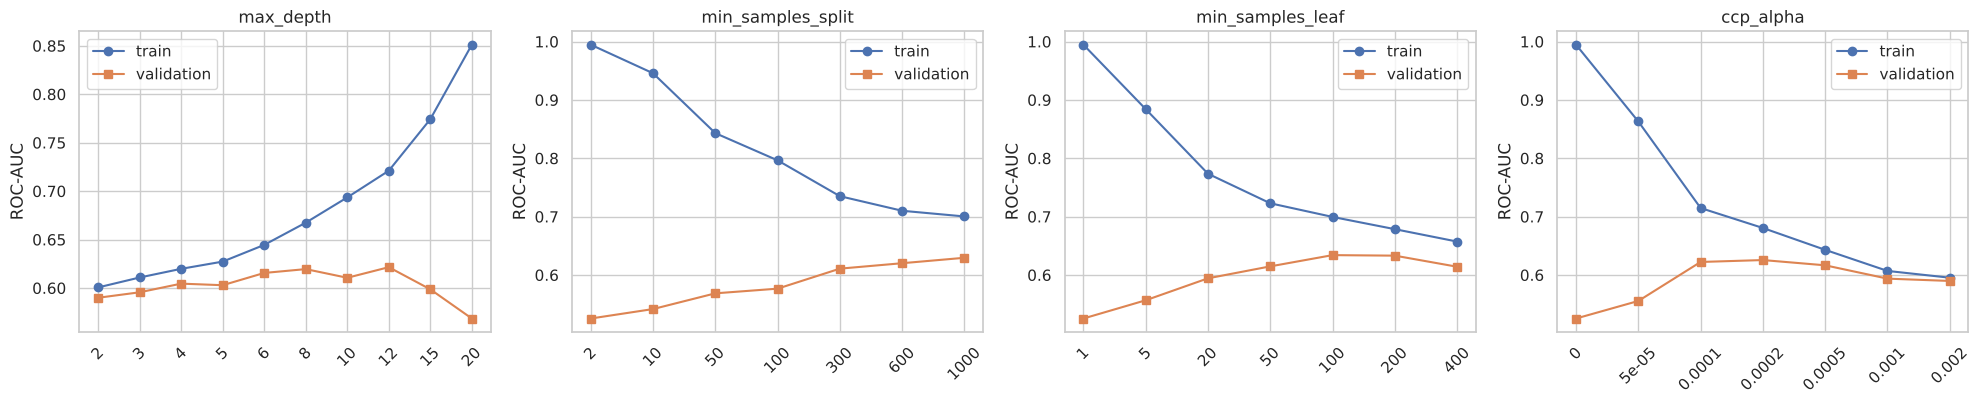

,max_depth,train AUC,validation AUC,leaves
0,2,0.6006,0.5899,4
1,3,0.6108,0.5956,8
2,4,0.6198,0.6045,16
3,5,0.6273,0.6029,32
4,6,0.6445,0.6155,60
5,8,0.6674,0.6195,150
6,10,0.6935,0.6106,313
7,12,0.7210,0.6215,546
8,15,0.7742,0.5986,1124
9,20,0.8511,0.5685,2354


In [3]:
enc = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200, sparse_output=False), CAT), ("num", "passthrough", NUM)])
Xtr = enc.fit_transform(train[CAT + NUM]); Xva = enc.transform(val[CAT + NUM]); Xte = enc.transform(test[CAT + NUM])
names = [n.replace("cat__", "").replace("num__", "") for n in enc.get_feature_names_out()]
ytr, yva, yte = train["is_failed_inspection"].values, val["is_failed_inspection"].values, test["is_failed_inspection"].values
print("Encoded features:", Xtr.shape[1])

def fit_eval(**params):
    m = DecisionTreeClassifier(random_state=42, **params).fit(Xtr, ytr)
    return m, roc_auc_score(ytr, m.predict_proba(Xtr)[:, 1]), roc_auc_score(yva, m.predict_proba(Xva)[:, 1])

# one factor at a time, the other settings at their defaults
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
sweeps = [("max_depth", [2, 3, 4, 5, 6, 8, 10, 12, 15, 20], {}), ("min_samples_split", [2, 10, 50, 100, 300, 600, 1000], {}),
          ("min_samples_leaf", [1, 5, 20, 50, 100, 200, 400], {}), ("ccp_alpha", [0, 0.00005, 0.0001, 0.0002, 0.0005, 0.001, 0.002], {})]
sweep_tables = {}
for a, (param, values, extra) in zip(ax, sweeps):
    rows = []
    for v in values:
        m, auc_tr, auc_va = fit_eval(**{param: v}); rows.append({param: v, "train AUC": auc_tr, "validation AUC": auc_va, "leaves": m.get_n_leaves()})
    t = pd.DataFrame(rows); sweep_tables[param] = t.copy()
    if param == "ccp_alpha":
        sweep_tables[param][param] = sweep_tables[param][param].map(lambda v: f"{v:g}")
    xs = range(len(values))
    a.plot(xs, t["train AUC"], marker="o", label="train"); a.plot(xs, t["validation AUC"], marker="s", label="validation")
    a.set_xticks(list(xs)); a.set_xticklabels([str(v) for v in values], rotation=45); a.set_title(param); a.set_ylabel("ROC-AUC"); a.legend()
plt.tight_layout(); plt.show()
sweep_tables["max_depth"].round(4)

In [4]:
print("min_samples_leaf (one factor):"); display(sweep_tables["min_samples_leaf"].round(4))
print("ccp_alpha (one factor):"); display(sweep_tables["ccp_alpha"].round(4))

min_samples_leaf (one factor):


,min_samples_leaf,train AUC,validation AUC,leaves
0,1,0.9946,0.5254,8057
1,5,0.8842,0.5566,3482
2,20,0.7735,0.5943,1022
3,50,0.7229,0.6147,398
4,100,0.6995,0.6340,206
5,200,0.6785,0.6331,99
6,400,0.6572,0.6141,52


ccp_alpha (one factor):


,ccp_alpha,train AUC,validation AUC,leaves
0,0,0.9946,0.5254,8057
1,5e-05,0.8630,0.5555,1770
2,0.0001,0.7147,0.6223,179
3,0.0002,0.6805,0.6256,53
4,0.0005,0.6431,0.6166,16
5,0.001,0.6069,0.5937,5
6,0.002,0.5953,0.5898,3


**Inference (investigating the tree settings, ROC-AUC on the 2024 validation year):**
- **max_depth:** the training AUC keeps rising (0.60 at depth 2 to 0.85 at depth 20) but the validation AUC peaks around depth 8-12 (0.62) and then falls to 0.57 at depth 20. Deep trees memorise the training years.
- **min_samples_leaf:** with 1 sample per leaf the tree has 8,057 leaves, a training AUC of 0.995 and a validation AUC of only 0.525 (almost random). The validation AUC is best at 100-200 samples per leaf (0.634 and 0.633).
- **min_samples_split:** a larger value acts like pruning: the validation AUC grows from about 0.53 (split 2) to about 0.63 (split 1000).
- **ccp_alpha (pruning):** a small penalty helps (0.6256 at 0.0002, 53 leaves); a large one underfits (0.5898 at 0.002, only 3 leaves).
- All four controls tell the same story: **an unrestricted tree over-fits badly and a well-restricted one generalises better, but the best validation AUC is only about 0.63.**

In [5]:
# grid search over the four settings together (ROC-AUC on the 2024 validation year)
import itertools, time
grid = list(itertools.product([3, 4, 5, 6, 8, 10, 12], [2, 50, 200], [1, 20, 50, 100, 200], [0, 0.0005, 0.001, 0.002]))
t0 = time.time(); rows = []
for depth, mss, msl, alpha in grid:
    m, auc_tr, auc_va = fit_eval(max_depth=depth, min_samples_split=mss, min_samples_leaf=msl, ccp_alpha=alpha)
    rows.append({"max_depth": depth, "min_samples_split": mss, "min_samples_leaf": msl, "ccp_alpha": alpha, "train AUC": auc_tr, "validation AUC": auc_va, "leaves": m.get_n_leaves()})
search = pd.DataFrame(rows).sort_values("validation AUC", ascending=False).reset_index(drop=True)
print(f"{len(grid)} combinations tried in {time.time() - t0:.0f} s")
display(search.head(8).round(4))
best = search.iloc[0]
BEST = dict(max_depth=int(best["max_depth"]), min_samples_split=int(best["min_samples_split"]), min_samples_leaf=int(best["min_samples_leaf"]), ccp_alpha=float(best["ccp_alpha"]))
print("Selected settings:", BEST)

420 combinations tried in 67 s


,max_depth,min_samples_split,min_samples_leaf,ccp_alpha,train AUC,validation AUC,leaves
0,8,200,200,0.0,0.6534,0.6357,37
1,8,2,200,0.0,0.6534,0.6357,37
2,8,50,200,0.0,0.6534,0.6357,37
3,12,200,20,0.0,0.6835,0.6357,107
4,12,2,100,0.0,0.6795,0.6355,112
5,12,200,100,0.0,0.6795,0.6355,112
6,12,50,100,0.0,0.6795,0.6355,112
7,12,2,200,0.0,0.6706,0.6351,69


Selected settings: {'max_depth': 8, 'min_samples_split': 200, 'min_samples_leaf': 200, 'ccp_alpha': 0.0}


**Inference:** 420 combinations were tried in about a minute. The best validation AUC is **0.6357**, and several combinations are practically tied (0.6351-0.6357), so there is a plateau and the choice is not sensitive. The simplest of the best settings was selected: **max_depth 8, min_samples_split 200, min_samples_leaf 200, no extra pruning**.

## 3. Final model: refit on 2022-2024, evaluate once on the 2025 test year

In [6]:
Xfit = np.vstack([Xtr, Xva]); yfit = np.concatenate([ytr, yva])
tree = DecisionTreeClassifier(random_state=42, **BEST).fit(Xfit, yfit)
proba = tree.predict_proba(Xte)[:, 1]

# threshold: the default 0.5 is shown, plus the threshold that maximises F1 on the VALIDATION year (model fitted on train only)
sel = DecisionTreeClassifier(random_state=42, **BEST).fit(Xtr, ytr)
p_va = sel.predict_proba(Xva)[:, 1]; prec, rec, thr = precision_recall_curve(yva, p_va)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None); thr_best = float(thr[np.argmax(f1s)])

def report(name, p, t):
    pred = (p >= t).astype(int); tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    return {"Model": name, "threshold": round(t, 3), "Accuracy": accuracy_score(yte, pred), "Precision": precision_score(yte, pred, zero_division=0), "Recall": recall_score(yte, pred),
            "F1": f1_score(yte, pred), "ROC-AUC": roc_auc_score(yte, p), "TN": tn, "FP": fp, "FN": fn, "TP": tp}
base = {"Model": "Baseline: always 'not failed'", "threshold": "-", "Accuracy": 1 - yte.mean(), "Precision": 0.0, "Recall": 0.0, "F1": 0.0, "ROC-AUC": 0.5, "TN": int((yte == 0).sum()), "FP": 0, "FN": int(yte.sum()), "TP": 0}
final = pd.DataFrame([base, report("Decision tree, threshold 0.5", proba, 0.5), report("Decision tree, validation-optimal threshold", proba, thr_best)])
print("Tree: %d leaves, depth %d" % (tree.get_n_leaves(), tree.get_depth()))
final.to_csv("../results/decision_tree_metrics.csv", index=False)
final.round(4)

Tree: 54 leaves, depth 8


,Model,threshold,Accuracy,Precision,Recall,F1,ROC-AUC,TN,FP,FN,TP
0,Baseline: always 'not failed',-,0.7887,0.0000,0.0000,0.0000,0.5000,12661,0,3391,0
1,"Decision tree, threshold 0.5",0.5,0.7836,0.3797,0.0386,0.0701,0.6354,12447,214,3260,131
2,"Decision tree, validation-optimal threshold",0.217,0.6005,0.2891,0.6107,0.3924,0.6354,7568,5093,1320,2071


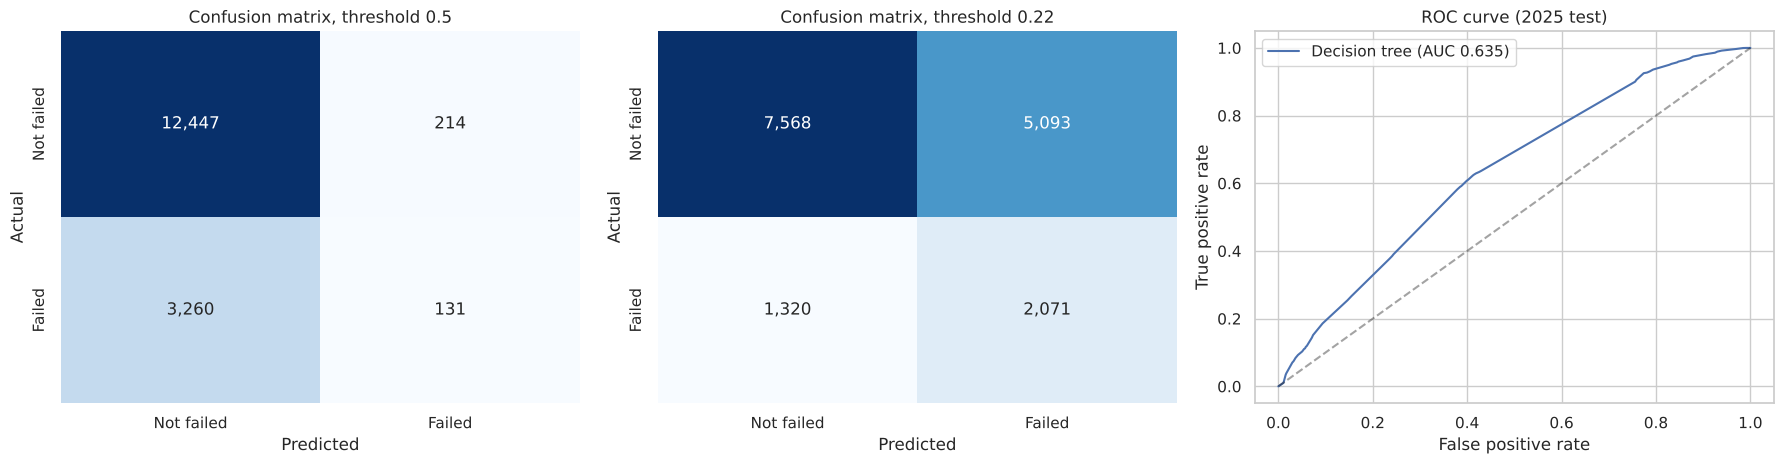

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for a, (t, title) in zip(ax[:2], [(0.5, "threshold 0.5"), (thr_best, f"threshold {thr_best:.2f}")]):
    cm = confusion_matrix(yte, (proba >= t).astype(int)); sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=a, xticklabels=["Not failed", "Failed"], yticklabels=["Not failed", "Failed"])
    a.set_title(f"Confusion matrix, {title}"); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
fpr, tpr, _ = roc_curve(yte, proba); ax[2].plot(fpr, tpr, label=f"Decision tree (AUC {roc_auc_score(yte, proba):.3f})"); ax[2].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate"); ax[2].set_title("ROC curve (2025 test)"); ax[2].legend()
plt.tight_layout(); plt.show()

Feature importance (top 12):


,importance
prior_inspection_result_Fail,0.2940
inspection_type_Complaint,0.1470
prior_violation_count,0.1282
days_since_prior_inspection,0.0999
zip_60617,0.0520
inspection_type_Canvass Re-Inspection,0.0461
facility_type_School,0.0425
prior_inspection_result_Pass,0.0398
area_Southwest,0.0232
zip_60625,0.0226


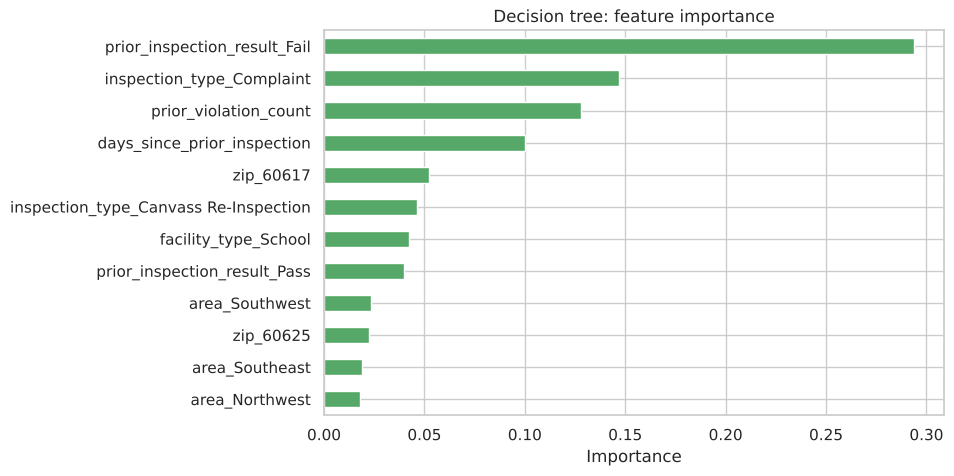

In [8]:
imp = pd.Series(tree.feature_importances_, index=names).sort_values(ascending=False)
imp.head(12).to_csv("../results/decision_tree_importance.csv", header=["importance"])
print("Feature importance (top 12):"); display(imp.head(12).round(4).to_frame("importance"))
plt.figure(figsize=(8, 5)); imp.head(12)[::-1].plot(kind="barh", color="#55A868"); plt.title("Decision tree: feature importance"); plt.xlabel("Importance"); plt.show()

**Inference (test year 2025, the model was fitted on 2022-2024):**
- **Baseline:** always predicting "not failed" is 78.9% accurate. The tree (54 leaves, depth 8) has a test **ROC-AUC of 0.635**, clearly above random (0.5) but far from a good classifier.
- **At the default threshold 0.5** the tree almost never predicts a fail: recall 3.9%, precision 38.0%, F1 0.07, and its accuracy (78.4%) is even slightly below the baseline. Accuracy is therefore a misleading measure here.
- **At the threshold that maximised F1 on the validation year (0.217)** it finds **61% of the failed inspections** (2,071 of 3,391) but with a precision of only 28.9%; it raises 5,093 false alarms and the accuracy drops to 60.1%. A health department could use this as a ranking, not as a decision.
- **Feature importance:** the most important predictors are the **result of the previous inspection** (Fail: 29%), a **complaint inspection** (15%), the **previous violation count** (13%) and the **days since the previous inspection** (10%). Then come ZIP 60617 (5%), canvass re-inspection (5%) and schools (4%). History and inspection type matter far more than the month or the weekday, which do not appear among the top features.

## 4. The trained tree and three actual decision paths

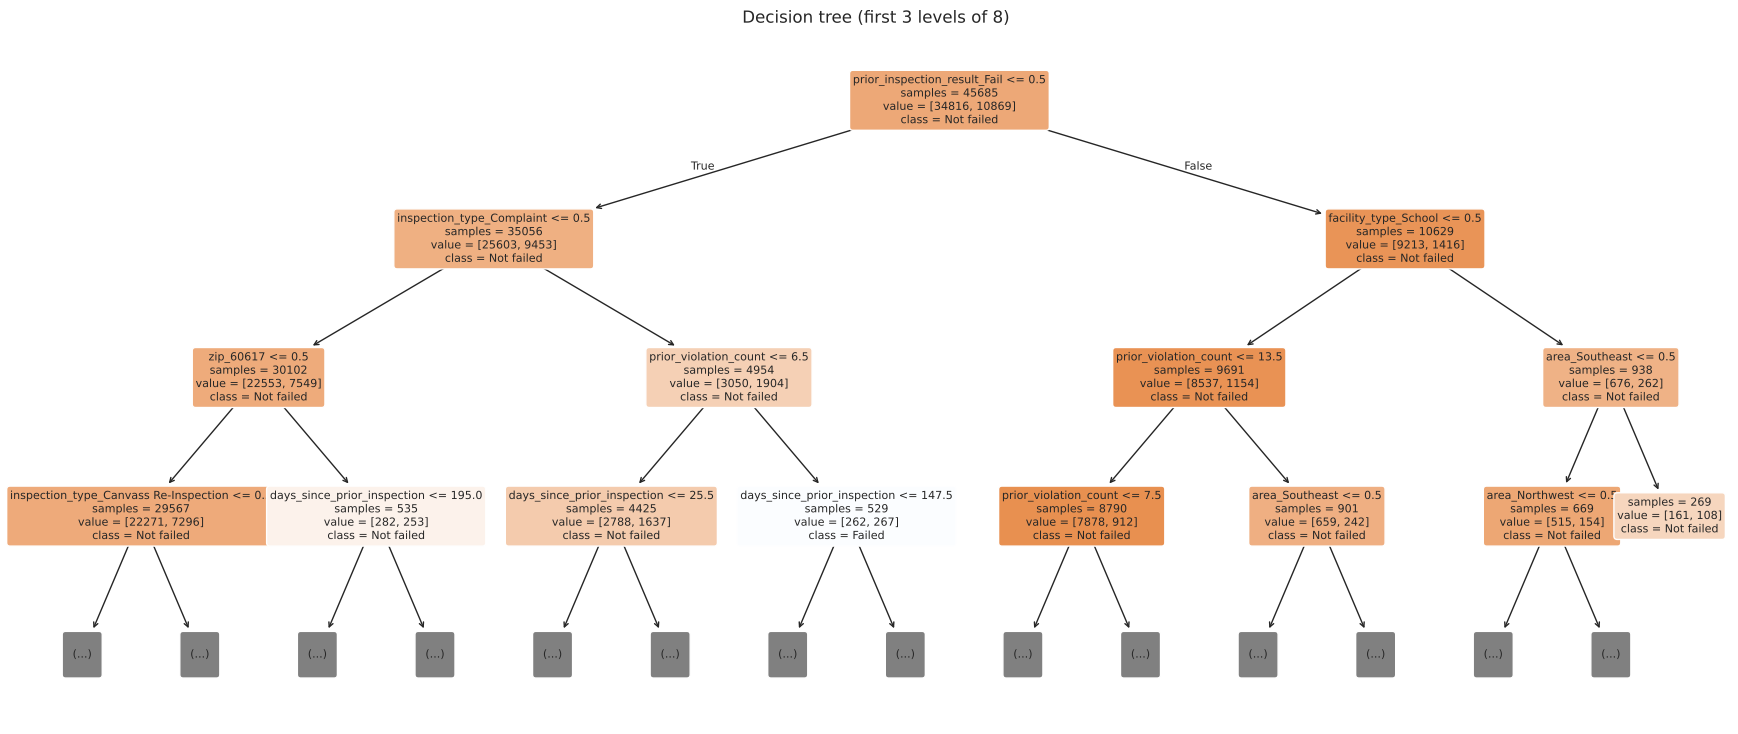

In [9]:
plt.figure(figsize=(22, 9))
plot_tree(tree, max_depth=3, feature_names=names, class_names=["Not failed", "Failed"], filled=True, rounded=True, fontsize=8, impurity=False, proportion=False)
plt.title("Decision tree (first 3 levels of %d)" % tree.get_depth()); plt.show()

In [10]:
# Decision paths: describe the leaves with the clearest signal (train+validation rows) and check them on the 2025 test year
leaf_fit, leaf_te = tree.apply(Xfit), tree.apply(Xte)
t_ = tree.tree_
def path_text(leaf):
    node_path = tree.decision_path(Xfit[leaf_fit == leaf][:1]).indices
    conds = []
    for a, b in zip(node_path[:-1], node_path[1:]):
        f = names[t_.feature[a]]; thr = t_.threshold[a]
        conds.append(f"{f} <= {thr:.1f}" if t_.children_left[a] == b else f"{f} > {thr:.1f}")
    return conds
leaves = pd.DataFrame({"leaf": np.unique(leaf_fit)})
leaves["n_fit"] = leaves["leaf"].map(pd.Series(leaf_fit).value_counts()); leaves["fail_rate_fit"] = leaves["leaf"].map(pd.Series(yfit).groupby(leaf_fit).mean())
leaves["n_test"] = leaves["leaf"].map(pd.Series(leaf_te).value_counts()).fillna(0).astype(int)
leaves["fail_rate_test"] = leaves["leaf"].map(pd.Series(yte).groupby(leaf_te).mean())
big = leaves[(leaves["n_fit"] >= 300) & (leaves["n_test"] >= 100)]
picks = {"HIGHEST fail rate": big.sort_values("fail_rate_fit", ascending=False).iloc[0], "LOWEST fail rate": big.sort_values("fail_rate_fit").iloc[0], "LARGEST group": big.sort_values("n_fit", ascending=False).iloc[0]}
paths = []
for label, r in picks.items():
    print(f"=== Path: {label} (leaf {int(r.leaf)})"); 
    for c in path_text(int(r.leaf)): print("   IF", c)
    print(f"   -> train+validation: {int(r.n_fit):,} inspections, {100 * r.fail_rate_fit:.1f}% failed | test 2025: {int(r.n_test):,} inspections, {100 * r.fail_rate_test:.1f}% failed\n")
    paths.append({"path": label, "conditions": " AND ".join(path_text(int(r.leaf))), "n (2022-24)": int(r.n_fit), "fail % (2022-24)": round(100 * r.fail_rate_fit, 1), "n (2025)": int(r.n_test), "fail % (2025)": round(100 * r.fail_rate_test, 1)})
pd.DataFrame(paths).to_csv("../results/decision_tree_paths.csv", index=False)
pd.DataFrame(paths)

=== Path: HIGHEST fail rate (leaf 61)
   IF prior_inspection_result_Fail <= 0.5
   IF inspection_type_Complaint > 0.5
   IF prior_violation_count > 6.5
   IF days_since_prior_inspection > 147.5
   -> train+validation: 327 inspections, 54.7% failed | test 2025: 140 inspections, 57.9% failed

=== Path: LOWEST fail rate (leaf 74)
   IF prior_inspection_result_Fail > 0.5
   IF facility_type_School <= 0.5
   IF prior_violation_count <= 13.5
   IF prior_violation_count <= 7.5
   IF days_since_prior_inspection <= 36.5
   IF area_Northwest > 0.5
   IF prior_violation_count <= 4.5
   IF prior_inspection_count <= 3.5
   -> train+validation: 1,398 inspections, 3.7% failed | test 2025: 208 inspections, 4.8% failed

=== Path: LARGEST group (leaf 8)
   IF prior_inspection_result_Fail <= 0.5
   IF inspection_type_Complaint <= 0.5
   IF zip_60617 <= 0.5
   IF inspection_type_Canvass Re-Inspection <= 0.5
   IF prior_inspection_result_Pass <= 0.5
   IF area_Southwest <= 0.5
   IF zip_60666 <= 0.5
   IF 

,path,conditions,n (2022-24),fail % (2022-24),n (2025),fail % (2025)
0,HIGHEST fail rate,prior_inspection_result_Fail <= 0.5 AND inspection_type_Complaint > 0.5 AND prior_violation_count > 6.5 AND days_sin...,327,54.7,140,57.9
1,LOWEST fail rate,prior_inspection_result_Fail > 0.5 AND facility_type_School <= 0.5 AND prior_violation_count <= 13.5 AND prior_viola...,1398,3.7,208,4.8
2,LARGEST group,prior_inspection_result_Fail <= 0.5 AND inspection_type_Complaint <= 0.5 AND zip_60617 <= 0.5 AND inspection_type_Ca...,10757,26.9,2360,27.5


**Inference (three actual decision paths, checked on the 2025 test year):**
1. **Highest fail rate (55-58%):** *the previous result was not a fail* AND *the inspection is a complaint inspection* AND *the previous inspection had more than 6 violations* AND *more than 147 days have passed since it*. A complaint visit to a facility that had many violations and has not been seen for 5 months fails 54.7% of the time in 2022-2024 (327 inspections) and 57.9% in 2025 (140 inspections), against 21% overall.
2. **Lowest fail rate (4-5%):** *the previous inspection was a fail* AND *not a school* AND *few violations then (at most 4)* AND *within 37 days* AND *Northwest area* AND *at most 3 earlier inspections*. This is a quick follow-up visit after a failed inspection: only 3.7% fail in 2022-2024 (1,398 inspections) and 4.8% in 2025 (208 inspections), so follow-up visits work.
3. **Largest group (27%):** *no previous fail* AND *not a complaint* AND *not ZIP 60617* AND *not a canvass re-inspection* AND *the previous result was not a pass* (so a conditional pass or no earlier inspection) AND *not in the Southwest or Northeast and not ZIP 60666*. These 10,757 inspections fail 26.9% of the time and 27.5% (2,360 inspections) in 2025, a little above the overall rate, so this group is not well separated.
The rates on the 2025 test inspections are close to those in the training years for all three paths, so the rules are stable over time even though the model as a whole is weak.

## Conclusion and limitations
1. A `DecisionTreeClassifier` was built on **information known before the inspection** and tuned on a separate validation year. Restricting the tree (depth, minimum leaf size, minimum split size, pruning) was essential: the unrestricted tree has a validation AUC of 0.53, the selected one 0.636.
2. On the 2025 test year the tree reaches an **ROC-AUC of 0.635**. At threshold 0.5 it is no better than always predicting "not failed" (78.4% against 78.9%); at the lower threshold 0.217 it finds 61% of the failures with 29% precision. Failure is **only weakly predictable in advance**.
3. What the tree learned is sensible: a **previous fail followed by a quick re-inspection rarely fails again**, **complaint inspections after a long gap and many earlier violations fail often**, and the facility's recent history is the strongest signal.
4. **Leakage was avoided:** no information from the current inspection (violations, band, result) is used and the history features use only earlier inspections.
5. Limitations: the history starts in 2022; the fail rate changed over time (24.9% in 2022 to 21.1% in 2025); the same facility appears in several rows; and what happens inside the facility on the day (the real cause of a fail) is not in the data. The tree should be used to **rank** inspections for attention, together with inspector judgement, not to decide them.